# 05 — 5-fold cross-validation training

Trains one preset on every fold (each fold = one model trained on the other four folds). Folds that are already
finished — e.g. fold 0 from notebook 04 — are reused, not retrained. Outputs:

* one checkpoint and one set of predictions per fold (`outputs/checkpoints/<run>/`, `outputs/preds/<run>/`)
* **out-of-fold (OOF)** predictions: every training image is predicted by the model that did not train on it,
  so OOF accuracy uses all 63,660 images as validation
* a submission that averages the test probabilities of the fold models (no TTA; TTA and ensembling are in notebook 07)

This is the longest notebook (≈ 2 h per fold for ConvNeXt-Tiny at 128 px on the M1 Pro); run it in the background
from a terminal, see README.md.

In [1]:
RUN = "convnext_tiny_shift"   # preset name
FOLDS = "0,1,2,3,4"           # folds to train
FORCE = False
MAKE_SUBMISSION = True

In [2]:
# Parameters
RUN = "convnext_tiny_shift"


In [3]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))  # the notebooks live in the repo root, next to src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

import torch
from sklearn.metrics import confusion_matrix

from src.config import CLASSES, EXPERIMENTS_CSV, PRESETS, SUBMISSIONS_CSV, get_device, make_config, make_dirs
from src.data import load_test_df
from src.engine import fit, get_preds
from src.models import count_params, create_model
from src.plots import plot_confusion, plot_history, savefig
from src.utils import accuracy, softmax, write_submission

make_dirs()
print("device:", get_device())

from src.utils import log_loss

folds = [int(f) for f in FOLDS.split(",")]
cfg = make_config(RUN)
cfg

device: mps


TrainConfig(run_name='convnext_tiny_shift', model_name='convnext_tiny.fb_in22k_ft_in1k', pretrained=True, img_size=128, resize_mode='squash', aug='shift', crop_scale_min=0.6, crop_ratio=(0.6, 1.67), lowres_p=0.3, epochs=10, batch_size=64, lr=0.0002, head_lr=0.001, weight_decay=0.05, warmup_epochs=1, label_smoothing=0.1, ema_decay=0.999, drop_rate=0.0, drop_path_rate=0.1, cnn_width=32, patience=4, amp=True, drop_degenerate=True, num_workers=6, seed=42, train_limit=0, notes='')

## 1. Training, fold by fold

In [4]:
histories = {}
for fold in folds:
    histories[fold] = fit(cfg, fold=fold, force=FORCE)

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

[convnext_tiny_shift fold 0] device=mps  train=50914  val=12732  steps/epoch=795


train:   0%|          | 0/795 [00:09<?, ?it/s]

val_clean:   0%|          | 0/100 [00:10<?, ?it/s]

...

val_shift:   0%|          | 0/100 [00:00<?, ?it/s]

epoch 10/10  train 0.4911/0.9889  clean 0.1305/0.9823  shift 0.1194/0.9861  796s


val_clean:   0%|          | 0/100 [00:00<?, ?it/s]

val_shift:   0%|          | 0/100 [00:00<?, ?it/s]

test:   0%|          | 0/231 [00:10<?, ?it/s]

## 2. Per-fold results and learning curves

In [5]:
ex = pd.read_csv(EXPERIMENTS_CSV)
ex = ex[(ex["run"] == RUN) & ex["fold"].isin(folds)].sort_values("fold")
display(ex[["fold", "best_epoch", "epochs_run", "train_acc", "val_clean_acc", "val_shift_acc",
            "val_clean_loss", "val_shift_loss", "minutes"]])
display(ex[["val_clean_acc", "val_shift_acc"]].agg(["mean", "std", "min", "max"]).round(4))

,fold,best_epoch,epochs_run,train_acc,val_clean_acc,val_shift_acc,val_clean_loss,val_shift_loss,minutes
0,0,7,10,0.9839,0.9838,0.9885,0.1222,0.1112,136.6
1,1,5,9,0.9761,0.9832,0.9883,0.1292,0.1187,121.5
2,2,7,10,0.9832,0.9819,0.9866,0.1274,0.1173,133.2
3,3,7,10,0.9834,0.9833,0.9870,0.1256,0.1163,133.2
4,4,6,10,0.9794,0.9841,0.9879,0.1257,0.1180,133.1


,val_clean_acc,val_shift_acc
mean,0.9833,0.9877
std,0.0008,0.0008
min,0.9819,0.9866
max,0.9841,0.9885


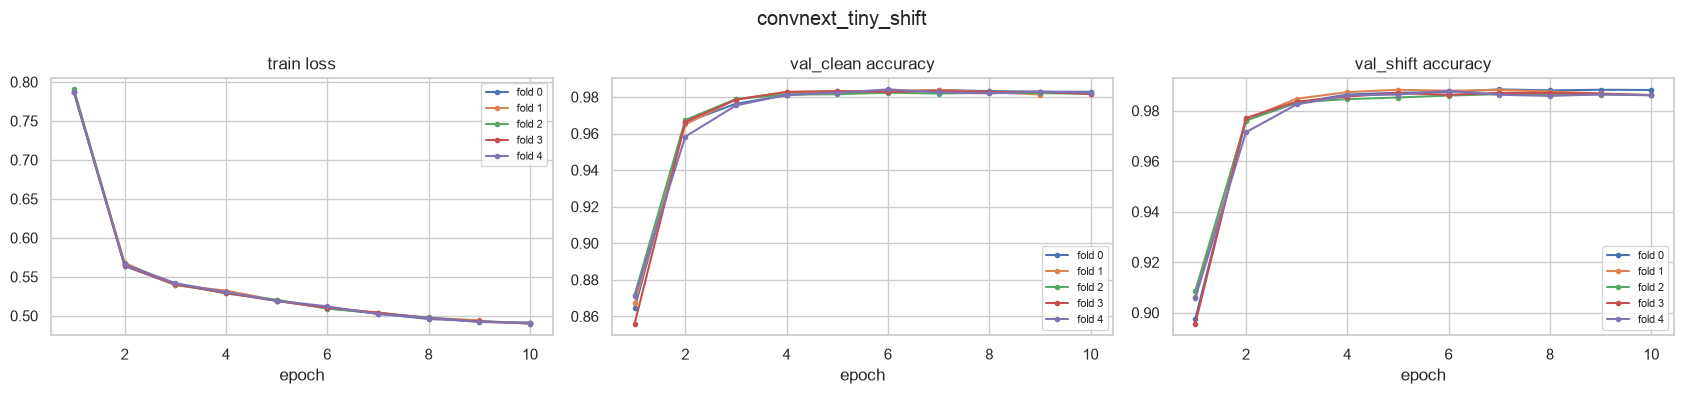

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for fold, hist in histories.items():
    axes[0].plot(hist["epoch"], hist["train_loss"], marker=".", label=f"fold {fold}")
    axes[1].plot(hist["epoch"], hist["val_clean_acc"], marker=".", label=f"fold {fold}")
    axes[2].plot(hist["epoch"], hist["val_shift_acc"], marker=".", label=f"fold {fold}")
for ax, t in zip(axes, ["train loss", "val_clean accuracy", "val_shift accuracy"]):
    ax.set_title(t)
    ax.set_xlabel("epoch")
    ax.legend(fontsize=8)
plt.suptitle(RUN)
plt.tight_layout()
savefig(f"05_folds_{RUN}")
plt.show()

> **Observations (to be written by me):**

## 3. Out-of-fold predictions

,val_clean,val_shift
images,63660.0000,63660.0000
accuracy,0.9833,0.9877
log loss,0.1260,0.1163


,val_clean,val_shift
CatEye,0.9955,0.9956
CatFace,0.9999,0.9996
CatMouth,0.9922,0.9869
CatNose,0.8849,0.9313
DogEye,0.9987,0.9986
DogFace,0.9998,1.0000
DogMouth,0.9938,0.9931
DogNose,0.9832,0.9831


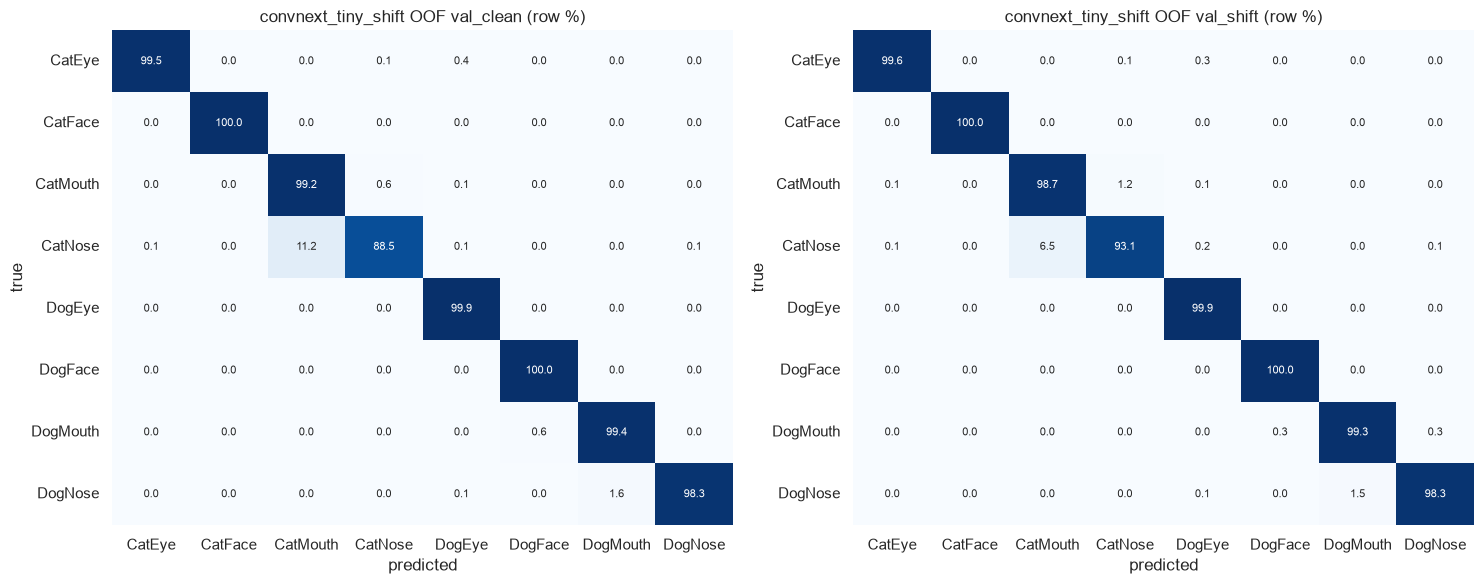

In [7]:
oof = {}
for split in ["val_clean", "val_shift"]:
    parts = [get_preds(RUN, f, split) for f in folds]
    oof[split] = dict(ids=np.concatenate([p[0] for p in parts]), probs=softmax(np.concatenate([p[1] for p in parts])),
                      labels=np.concatenate([p[2] for p in parts]))
summary = pd.DataFrame({split: {"images": len(o["labels"]), "accuracy": accuracy(o["probs"], o["labels"]),
                                "log loss": log_loss(o["probs"], o["labels"])} for split, o in oof.items()})
display(summary.round(4))

per_class = pd.DataFrame({split: [(o["probs"].argmax(1)[o["labels"] == k] == k).mean() for k in range(len(CLASSES))]
                          for split, o in oof.items()}, index=CLASSES)
display(per_class.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (split, o) in zip(axes, oof.items()):
    plot_confusion(confusion_matrix(o["labels"], o["probs"].argmax(1), labels=range(len(CLASSES))), CLASSES,
                   title=f"{RUN} OOF {split}", ax=ax)
plt.tight_layout()
savefig(f"05_oof_confusion_{RUN}")
plt.show()

> **Observations (to be written by me):**

## 4. Submission: average of the fold models' test probabilities (no TTA)

In [8]:
if MAKE_SUBMISSION:
    test_df = load_test_df()
    probs = np.mean([softmax(get_preds(RUN, f, "test")[1]) for f in folds], axis=0)
    agree = np.mean([(softmax(get_preds(RUN, f, "test")[1]).argmax(1) == probs.argmax(1)).mean() for f in folds])
    print(f"mean agreement of single fold models with the fold average on test: {agree:.4f}")
    write_submission(test_df, probs, f"{RUN}_cv{len(folds)}", runs=RUN,
                     val_clean=round(summary.loc["accuracy", "val_clean"], 4),
                     val_shift=round(summary.loc["accuracy", "val_shift"], 4),
                     notes=f"mean of folds {FOLDS}, no TTA (val = OOF)")
    display(pd.read_csv(SUBMISSIONS_CSV))

mean agreement of single fold models with the fold average on test: 0.9895
wrote /Users/avathanshubhat/Documents/AUT/Y3S2/ENGE707 - Data Engineering & AI/Kaggle Contest/ENGE707_Kaggle_Competition/submissions/convnext_tiny_shift_cv5.csv  (29443 rows, validated)
{'CatEye': 0.213, 'DogEye': 0.19, 'CatMouth': 0.127, 'CatFace': 0.106, 'DogMouth': 0.1, 'DogFace': 0.096, 'DogNose': 0.086, 'CatNose': 0.081}


,file,created,runs,val_clean,val_shift,lb_public,lb_private,notes
0,convnext_tiny_shift_fold0.csv,2026-10-07 23:42,convnext_tiny_shift,0.9838,0.9885,0.9598,NaN,"fold 0 only, no TTA (made during the 05 run)"
1,convnext_tiny_shift_cv5.csv,2026-10-08 08:23,convnext_tiny_shift,0.9833,0.9877,NaN,NaN,"mean of folds 0,1,2,3,4, no TTA (val = OOF)"
